# Гипотеза: Средний уровень удовлетворенности уволившихся равен среднему уровню оставшихся

## Данные
Таблица `V4_Employee_cleaned.csv` (предобработанная на этапе V4).

## Цель
Проверить гипотезу: средний интегральный уровень удовлетворенности уволившихся сотрудников (`attrition_flag = 1`) равен среднему уровню удовлетворенности оставшихся сотрудников (`attrition_flag = 0`).

В качестве интегрального показателя используется `satisfaction_score` — среднее трех оценок: `environmentsatisfaction`, `jobsatisfaction`, `relationshipsatisfaction`.

In [21]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Загрузка данных

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os
print(os.listdir('/content/drive/MyDrive'))

print(os.listdir('/content/drive/MyDrive/Проект команды 3'))

path = '/content/drive/MyDrive/Проект команды 3/'
df = pd.read_csv(path + "V4_Employee_cleaned.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Getting started.pdf', 'Macro Seminar 5.gdoc', 'China US trade war.gdoc', 'november.gdoc', 'MOC UZ.gdoc', 'MOC presentation.gslides', 'MOC intensive course.gdoc', 'List of Books (2020).gdoc', 'ZARINAADT   18 AUGSVOPRG.eml', 'SKODA seminar .gdoc', 'COLOMBO.gdoc', 'RUspina.gdoc', 'MACRO review .gdoc', 'micro questions.gdoc', 'University of Economics, Prague.pdf', 'plan.gdoc', 'Study material .gdoc', 'students stats.gdoc', 'BLACK HOLES.gdoc', 'bangladesh.gdoc', 'TRANSCRIPT OF ACADEMIC RECORDS.pdf', 'Untitled document (17).gdoc', '33.gdoc', '33 (2).pdf', 'Scan 001.PDF', '33 (2).gdoc', 'Untitled document (16).gdoc', 'специализация .gdoc', 'Untitled document (15).gdoc', '6.gdoc', 'финансы.gdoc', 'Особенности принятия управленческих решений в различных областях экономики..gslides', 'Анализ японских методов управления.gdoc', 'фнко.gdoc', 'Организация финансов неком

In [11]:
print(f"Загружено строк: {len(df)}")
print(f"Колонки: {list(df.columns)}")

Загружено строк: 1470
Колонки: ['employeeid', 'firstname', 'lastname', 'gender', 'age', 'businesstravel', 'department', 'distancefromhome_(km)', 'state', 'ethnicity', 'education', 'educationfield', 'jobrole', 'maritalstatus', 'salary', 'stockoptionlevel', 'overtime', 'hiredate', 'attrition', 'yearsatcompany', 'yearsinmostrecentrole', 'yearssincelastpromotion', 'yearswithcurrmanager', 'performanceid', 'reviewdate', 'environmentsatisfaction', 'jobsatisfaction', 'relationshipsatisfaction', 'trainingopportunitieswithinyear', 'trainingopportunitiestaken', 'worklifebalance', 'selfrating', 'managerrating', 'educationlevelid', 'educationlevel', 'ratingid', 'ratinglevel', 'satisfactionid', 'satisfactionlevel', 'review_date_anomaly', 'training_anomaly', 'rating_missing', 'age_group', 'salary_band', 'satisfaction_score', 'attrition_flag']


## Параметры (фиксируются ДО анализа)

In [14]:
# =================== ПАРАМЕТРЫ (фиксируются ДО анализа) ===================
ALPHA = 0.05                         # уровень статистической значимости
PRACTICAL_SIGNIFICANCE = 0.20        # минимальная практически значимая разница средних на шкале 1–5
TARGET = "attrition_flag"            # 0 = остался, 1 = уволился
PREDICTOR = "satisfaction_score"     # интегральная удовлетворенность (среднее трех шкал)
EMPLOYEE_KEY = "employeeid"          # единица наблюдения
# ===========================================================================

print(f"Уровень значимости alpha = {ALPHA}")
print(f"Порог практической значимости = {PRACTICAL_SIGNIFICANCE} балла по шкале 1–5")

Уровень значимости alpha = 0.05
Порог практической значимости = 0.2 балла по шкале 1–5


## 0. Структура данных (единица наблюдения, гранулярность, ключи)

In [15]:
print("=" * 70)
print("0. СТРУКТУРА ДАННЫХ")
print("=" * 70)
print(f"Размер таблицы: {df.shape[0]} строк × {df.shape[1]} столбцов")
print(f"Единица наблюдения: {EMPLOYEE_KEY} (один сотрудник)")
print(f"Ключ уникален: {df[EMPLOYEE_KEY].is_unique}")
print(f"Дубликаты ключа: {df.duplicated(subset=[EMPLOYEE_KEY]).sum()}")
print("Гранулярность: одна строка = один сотрудник")

print("\nТипы ключевых полей:")
for col in [EMPLOYEE_KEY, PREDICTOR, TARGET, "environmentsatisfaction",
            "jobsatisfaction", "relationshipsatisfaction", "department", "jobrole"]:
    if col in df.columns:
        print(f"  {col}: {df[col].dtype}")

0. СТРУКТУРА ДАННЫХ
Размер таблицы: 1470 строк × 46 столбцов
Единица наблюдения: employeeid (один сотрудник)
Ключ уникален: True
Дубликаты ключа: 0
Гранулярность: одна строка = один сотрудник

Типы ключевых полей:
  employeeid: object
  satisfaction_score: float64
  attrition_flag: int64
  environmentsatisfaction: float64
  jobsatisfaction: float64
  relationshipsatisfaction: float64
  department: object
  jobrole: object


## 1. Пропуски и специальные значения

In [16]:
print("\n" + "=" * 70)
print("1. ПРОПУСКИ И СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ")
print("=" * 70)

key_cols = [PREDICTOR, TARGET, "environmentsatisfaction",
            "jobsatisfaction", "relationshipsatisfaction",
            "department", "jobrole"]
for col in key_cols:
    if col in df.columns:
        nan_cnt = int(df[col].isna().sum())
        print(f"  {col}: пропусков = {nan_cnt} ({nan_cnt/len(df)*100:.1f}%)")

print(f"\nДиапазон {PREDICTOR}: {df[PREDICTOR].min()} - {df[PREDICTOR].max()}")
print(f"Уникальные значения {TARGET}: {sorted(df[TARGET].dropna().unique())}")

bad_pred = df[~df[PREDICTOR].between(1, 5) & df[PREDICTOR].notna()]
bad_tgt = df[~df[TARGET].isin([0, 1]) & df[TARGET].notna()]
print(f"\n{PREDICTOR} вне диапазона 1–5: {len(bad_pred)} строк")
print(f"{TARGET} не 0/1: {len(bad_tgt)} строк")


1. ПРОПУСКИ И СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ
  satisfaction_score: пропусков = 381 (25.9%)
  attrition_flag: пропусков = 0 (0.0%)
  environmentsatisfaction: пропусков = 381 (25.9%)
  jobsatisfaction: пропусков = 381 (25.9%)
  relationshipsatisfaction: пропусков = 381 (25.9%)
  department: пропусков = 0 (0.0%)
  jobrole: пропусков = 0 (0.0%)

Диапазон satisfaction_score: 1.0 - 5.0
Уникальные значения attrition_flag: [np.int64(0), np.int64(1)]

satisfaction_score вне диапазона 1–5: 0 строк
attrition_flag не 0/1: 0 строк


## 2. Временное и объектное покрытие, ограничения датасета

In [17]:
print("\n" + "=" * 70)
print("2. ПОКРЫТИЕ И ОГРАНИЧЕНИЯ")
print("=" * 70)
if "reviewdate" in df.columns:
    df["reviewdate"] = pd.to_datetime(df["reviewdate"], errors="coerce")
    print(f"reviewdate: min = {df['reviewdate'].min()}, max = {df['reviewdate'].max()}, пропусков = {int(df['reviewdate'].isna().sum())}")
print(f"Отделов: {df['department'].nunique() if 'department' in df.columns else 'н/д'}")
print(f"Должностей: {df['jobrole'].nunique() if 'jobrole' in df.columns else 'н/д'}")
print("Ограничение: данные наблюдательные; выявленная связь не доказывает причинность.")


2. ПОКРЫТИЕ И ОГРАНИЧЕНИЯ
reviewdate: min = 2013-04-12 00:00:00, max = 2022-11-21 00:00:00, пропусков = 381
Отделов: 3
Должностей: 13
Ограничение: данные наблюдательные; выявленная связь не доказывает причинность.


## 3. Формирование выборок для проверки гипотезы

In [18]:
print("\n" + "=" * 70)
print("3. ФОРМИРОВАНИЕ ВЫБОРОК")
print("=" * 70)

analysis = df[[EMPLOYEE_KEY, PREDICTOR, TARGET]].copy()
analysis[PREDICTOR] = pd.to_numeric(analysis[PREDICTOR], errors="coerce")
analysis[TARGET] = pd.to_numeric(analysis[TARGET], errors="coerce")

# В анализ включаем только корректные значения индекса и флага увольнения
analysis = analysis[
    analysis[TARGET].isin([0, 1]) &
    analysis[PREDICTOR].between(1, 5)
].dropna(subset=[PREDICTOR, TARGET]).copy()

left = analysis.loc[analysis[TARGET] == 1, PREDICTOR]   # уволившиеся
stayed = analysis.loc[analysis[TARGET] == 0, PREDICTOR] # оставшиеся

print(f"Наблюдений после очистки: {len(analysis)}")
print(f"Уволившиеся (attrition_flag=1): {len(left)}")
print(f"Оставшиеся (attrition_flag=0): {len(stayed)}")
print(f"Исключено строк с пропусками/некорректными значениями: {len(df) - len(analysis)}")

if len(left) < 2 or len(stayed) < 2:
    raise ValueError("Недостаточно наблюдений в одной из групп для проведения теста.")


3. ФОРМИРОВАНИЕ ВЫБОРОК
Наблюдений после очистки: 1089
Уволившиеся (attrition_flag=1): 176
Оставшиеся (attrition_flag=0): 913
Исключено строк с пропусками/некорректными значениями: 381


## 4. Описательная статистика: средние значения удовлетворенности

In [19]:
print("\n" + "=" * 70)
print("4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
print("=" * 70)

summary = analysis.groupby(TARGET)[PREDICTOR].agg(
    count="count", mean="mean", median="median",
    std="std", min="min", max="max"
).rename(index={0: "Оставшиеся", 1: "Уволившиеся"})
display(summary.round(3))

mean_left = left.mean()
mean_stayed = stayed.mean()
mean_diff = mean_left - mean_stayed

print(f"Средняя удовлетворенность уволившихся: {mean_left:.3f} (n={len(left)})")
print(f"Средняя удовлетворенность оставшихся: {mean_stayed:.3f} (n={len(stayed)})")
print(f"Разница средних (уволившиеся − оставшиеся): {mean_diff:.3f} балла")


4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА


,count,mean,median,std,min,max
attrition_flag,,,,,,
Оставшиеся,913,3.499,3.67,0.719,1.00,5.0
Уволившиеся,176,3.496,3.67,0.709,1.33,5.0


Средняя удовлетворенность уволившихся: 3.496 (n=176)
Средняя удовлетворенность оставшихся: 3.499 (n=913)
Разница средних (уволившиеся − оставшиеся): -0.003 балла


## 5. Статистическая значимость

In [22]:
print("\n" + "=" * 70)
print("5. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ")
print("=" * 70)

# H0: средние значения в двух группах равны
# H1: средние значения различаются
# Двусторонний t-тест Уэлча: не требует равенства дисперсий групп
t_stat, p_t = stats.ttest_ind(left, stayed, equal_var=False, alternative="two-sided")

# Доверительный интервал разницы средних по формуле Уэлча
n1, n0 = len(left), len(stayed)
v1, v0 = left.var(ddof=1), stayed.var(ddof=1)
se_diff = np.sqrt(v1/n1 + v0/n0)
df_welch = (v1/n1 + v0/n0)**2 / ((v1/n1)**2/(n1-1) + (v0/n0)**2/(n0-1))
t_crit = stats.t.ppf(1 - ALPHA/2, df_welch)
ci_low = mean_diff - t_crit * se_diff
ci_high = mean_diff + t_crit * se_diff

print(f"Welch t-test: t = {t_stat:.3f}, df = {df_welch:.1f}, p = {p_t:.5f}")
print(f"95%-й доверительный интервал разницы средних: [{ci_low:.3f}; {ci_high:.3f}]")

if p_t < ALPHA:
    print("Результат: различие средних статистически значимо (H0 отвергается).")
else:
    print("Результат: статистически значимых различий средних не обнаружено (нет оснований отвергнуть H0).")

# Дополнительный непараметрический тест для порядковой шкалы
u_stat, p_mw = stats.mannwhitneyu(left, stayed, alternative="two-sided")
print(f"Манна — Уитни: U = {u_stat:.1f}, p = {p_mw:.5f}")


5. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ
Welch t-test: t = -0.045, df = 249.3, p = 0.96424
95%-й доверительный интервал разницы средних: [-0.118; 0.113]
Результат: статистически значимых различий средних не обнаружено (нет оснований отвергнуть H0).
Манна — Уитни: U = 80401.5, p = 0.98797


## 6. Размер эффекта и практическая значимость (порог задан ДО анализа)

In [23]:
print("\n" + "=" * 70)
print("6. ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ")
print("=" * 70)

# Cohen's d с объединенным стандартным отклонением
pooled_sd = np.sqrt(((n1 - 1)*v1 + (n0 - 1)*v0) / (n1 + n0 - 2))
cohens_d = mean_diff / pooled_sd if pooled_sd > 0 else np.nan

print(f"Порог практически значимого эффекта: {PRACTICAL_SIGNIFICANCE} балла")
print(f"Полученная разница средних: {mean_diff:.3f} балла")
print(f"Практически значимый эффект: {'ДА' if abs(mean_diff) >= PRACTICAL_SIGNIFICANCE else 'НЕТ'}")
print(f"Cohen's d: {cohens_d:.3f}")


6. ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ
Порог практически значимого эффекта: 0.2 балла
Полученная разница средних: -0.003 балла
Практически значимый эффект: НЕТ
Cohen's d: -0.004


## 7. Визуализация распределений и средних


7. ВИЗУАЛИЗАЦИЯ


/tmp/ipykernel_452/3908742992.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([left, stayed], labels=["Уволившиеся", "Оставшиеся"], showmeans=True)


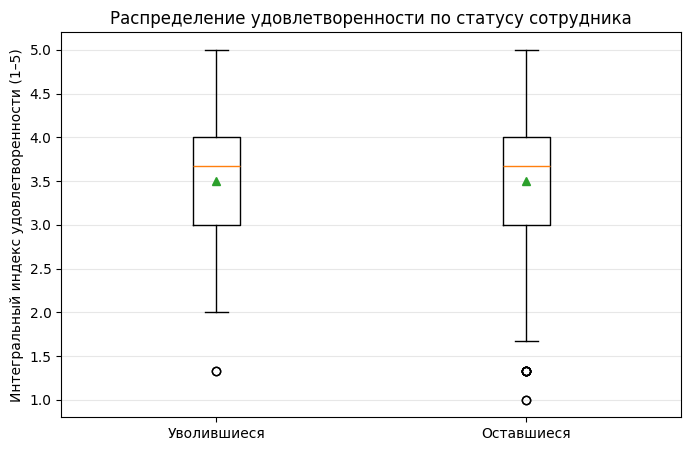

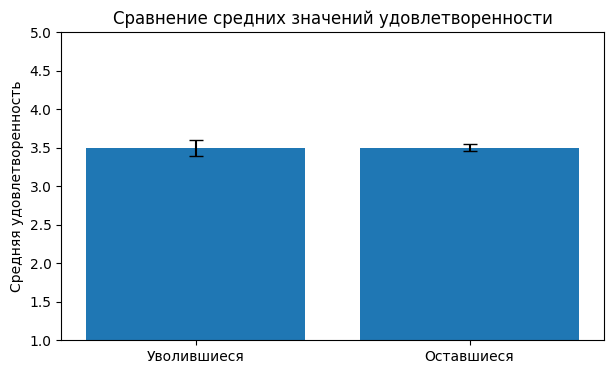

In [24]:
print("\n" + "=" * 70)
print("7. ВИЗУАЛИЗАЦИЯ")
print("=" * 70)

plt.figure(figsize=(8, 5))
plt.boxplot([left, stayed], labels=["Уволившиеся", "Оставшиеся"], showmeans=True)
plt.ylabel("Интегральный индекс удовлетворенности (1–5)")
plt.title("Распределение удовлетворенности по статусу сотрудника")
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
means = [mean_left, mean_stayed]
ses = [stats.sem(left), stats.sem(stayed)]
plt.bar(["Уволившиеся", "Оставшиеся"], means, yerr=[1.96*x for x in ses], capsize=5)
plt.ylabel("Средняя удовлетворенность")
plt.title("Сравнение средних значений удовлетворенности")
plt.ylim(1, 5)
plt.show()

## 8. Перепроверка по сегментам (отделы)

In [25]:
print("\n" + "=" * 70)
print("8. ПЕРЕПРОВЕРКА ПО СЕГМЕНТАМ (ОТДЕЛЫ)")
print("=" * 70)

strata_rows = []
if "department" in analysis.columns:
    # Добавим department к анализируемой таблице для сегментации
    seg = df[[EMPLOYEE_KEY, "department", PREDICTOR, TARGET]].copy()
    seg[PREDICTOR] = pd.to_numeric(seg[PREDICTOR], errors="coerce")
    seg[TARGET] = pd.to_numeric(seg[TARGET], errors="coerce")
    seg = seg[seg[TARGET].isin([0, 1]) & seg[PREDICTOR].between(1, 5)].dropna(subset=["department", PREDICTOR, TARGET])

    for dept, sub in seg.groupby("department"):
        a = sub.loc[sub[TARGET] == 1, PREDICTOR]
        b = sub.loc[sub[TARGET] == 0, PREDICTOR]
        if len(a) >= 2 and len(b) >= 2:
            strata_rows.append({
                "department": dept,
                "n_left": len(a), "mean_left": round(a.mean(), 3),
                "n_stayed": len(b), "mean_stayed": round(b.mean(), 3),
                "diff_mean": round(a.mean() - b.mean(), 3)
            })

if strata_rows:
    strata_df = pd.DataFrame(strata_rows).sort_values("diff_mean", ascending=False)
    print(strata_df.to_string(index=False))
else:
    print("Недостаточно данных для сравнения по отделам.")

print("Примечание: сегментный анализ является дополнительным описательным анализом.")


8. ПЕРЕПРОВЕРКА ПО СЕГМЕНТАМ (ОТДЕЛЫ)
Недостаточно данных для сравнения по отделам.
Примечание: сегментный анализ является дополнительным описательным анализом.


## 9. Наблюдение / Интерпретация / Влияние / Ограничение

In [26]:
print("\n" + "=" * 70)
print("9. НАБЛЮДЕНИЕ / ИНТЕРПРЕТАЦИЯ / ВЛИЯНИЕ / ОГРАНИЧЕНИЕ")
print("=" * 70)

print(f"1) Наблюдение: средняя удовлетворенность уволившихся = {mean_left:.3f}, оставшихся = {mean_stayed:.3f}.")
print(f"2) Разница средних (уволившиеся − оставшиеся) = {mean_diff:.3f} балла.")
print(f"3) Интерпретация: p-value теста Уэлча = {p_t:.5f}; "
      f"{'различие статистически значимо' if p_t < ALPHA else 'статистически значимое различие не выявлено'}.")
print("4) Ограничение: поперечные наблюдательные данные не позволяют установить причинно-следственную связь.")
print("5) Дополнительное ограничение: satisfaction_score усредняет три разных аспекта удовлетворенности;")
print("   результат по интегральному индексу может скрывать различия между отдельными компонентами.")


9. НАБЛЮДЕНИЕ / ИНТЕРПРЕТАЦИЯ / ВЛИЯНИЕ / ОГРАНИЧЕНИЕ
1) Наблюдение: средняя удовлетворенность уволившихся = 3.496, оставшихся = 3.499.
2) Разница средних (уволившиеся − оставшиеся) = -0.003 балла.
3) Интерпретация: p-value теста Уэлча = 0.96424; статистически значимое различие не выявлено.
4) Ограничение: поперечные наблюдательные данные не позволяют установить причинно-следственную связь.
5) Дополнительное ограничение: satisfaction_score усредняет три разных аспекта удовлетворенности;
   результат по интегральному индексу может скрывать различия между отдельными компонентами.


## 10. Итоговый вердикт

In [27]:
print("\n" + "=" * 70)
print("10. ИТОГОВЫЙ ВЕРДИКТ")
print("=" * 70)

# Формируем две группы сотрудников
left = df.loc[df["attrition_flag"] == 1, "satisfaction_score"].dropna()
stayed = df.loc[df["attrition_flag"] == 0, "satisfaction_score"].dropna()

# Рассчитываем разницу средних
mean_diff = left.mean() - stayed.mean()

pract_significant = abs(mean_diff) >= PRACTICAL_SIGNIFICANCE
stat_significant = p_t < ALPHA

if stat_significant and pract_significant:
    verdict = "РАЗЛИЧИЕ ПОДТВЕРЖДЕНО И ПРАКТИЧЕСКИ ЗНАЧИМО"
    rec = "Рассмотреть удовлетворенность как один из факторов, связанных с текучестью; дополнительно изучить три компонента индекса отдельно."
elif stat_significant and not pract_significant:
    verdict = "СТАТИСТИЧЕСКИ ЗНАЧИМО, НО ПРАКТИЧЕСКИ НЕЗНАЧИТЕЛЬНО"
    rec = "Разница обнаружена, но ее величина ниже заранее заданного порога; не делать сильных управленческих выводов."
elif not stat_significant and pract_significant:
    verdict = "НЕОПРЕДЕЛЕННЫЙ РЕЗУЛЬТАТ"
    rec = "Наблюдаемая разница достигает практического порога, но статистических доказательств недостаточно; нужны дополнительные данные."
else:
    verdict = "СТАТИСТИЧЕСКИ ЗНАЧИМОЕ РАЗЛИЧИЕ НЕ ВЫЯВЛЕНО"
    rec = "Нет достаточных оснований утверждать, что средние уровни удовлетворенности различаются; это не доказывает их полного равенства."

print(f"Вердикт: {verdict}")
print(f"Рекомендация заказчику: {rec}")
print(f"Критерий статистической значимости: p < {ALPHA}")
print(f"Порог практической значимости: разница средних ≥ {PRACTICAL_SIGNIFICANCE} балла")


10. ИТОГОВЫЙ ВЕРДИКТ
Вердикт: СТАТИСТИЧЕСКИ ЗНАЧИМОЕ РАЗЛИЧИЕ НЕ ВЫЯВЛЕНО
Рекомендация заказчику: Нет достаточных оснований утверждать, что средние уровни удовлетворенности различаются; это не доказывает их полного равенства.
Критерий статистической значимости: p < 0.05
Порог практической значимости: разница средних ≥ 0.2 балла


## 11. Резюме

**1. Сформулированная гипотеза**

Средний интегральный уровень удовлетворенности уволившихся сотрудников равен среднему интегральному уровню удовлетворенности оставшихся сотрудников.

**2. Статистические гипотезы**

- H₀: μ₁ = μ₀ — средние значения удовлетворенности равны.
- H₁: μ₁ ≠ μ₀ — средние значения удовлетворенности различаются.

Где μ₁ — среднее для уволившихся, μ₀ — среднее для оставшихся.

**3. План проверки гипотезы**

1. Загрузить `V4_Employee_cleaned.csv`.
2. Проверить структуру данных, единицу наблюдения и уникальность `employeeid`.
3. Проверить пропуски и допустимые значения `satisfaction_score` и `attrition_flag`.
4. Сформировать две независимые группы: уволившиеся (1) и оставшиеся (0).
5. Рассчитать описательные статистики и разницу средних.
6. Провести двусторонний t-тест Уэлча при α = 0,05.
7. Рассчитать 95%-й доверительный интервал разницы средних.
8. Дополнительно провести критерий Манна — Уитни.
9. Оценить размер и практическую значимость эффекта.
10. Сформулировать итоговый вывод с учетом ограничений.

**4. Интерпретация**

Если p-value t-теста Уэлча < 0,05, нулевая гипотеза отвергается: средние статистически значимо различаются. Если p-value ≥ 0,05, нет достаточных оснований отвергнуть H₀. Это не означает, что средние доказанно равны.

**5. Ограничения**

`Satisfaction_score` — составной индекс, рассчитанный как среднее трех оценок: `environmentsatisfaction`, `jobsatisfaction`, `relationshipsatisfaction`. Поэтому общий результат не показывает, какой именно компонент связан с различиями. Анализ не устанавливает причинность.